In [5]:
%pip install deepface tf-keras

In [6]:
%pip install opencv-python-headless==4.10.0.84

In [31]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import Sequential
from sklearn.feature_extraction.text import TfidfVectorizer
from deepface import DeepFace
from deepface import DeepFace
from google.colab import files
from IPython.display import display
from PIL import Image
import ast
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from typing import Text
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

Saving IMG_9443.jpeg to IMG_9443.jpeg


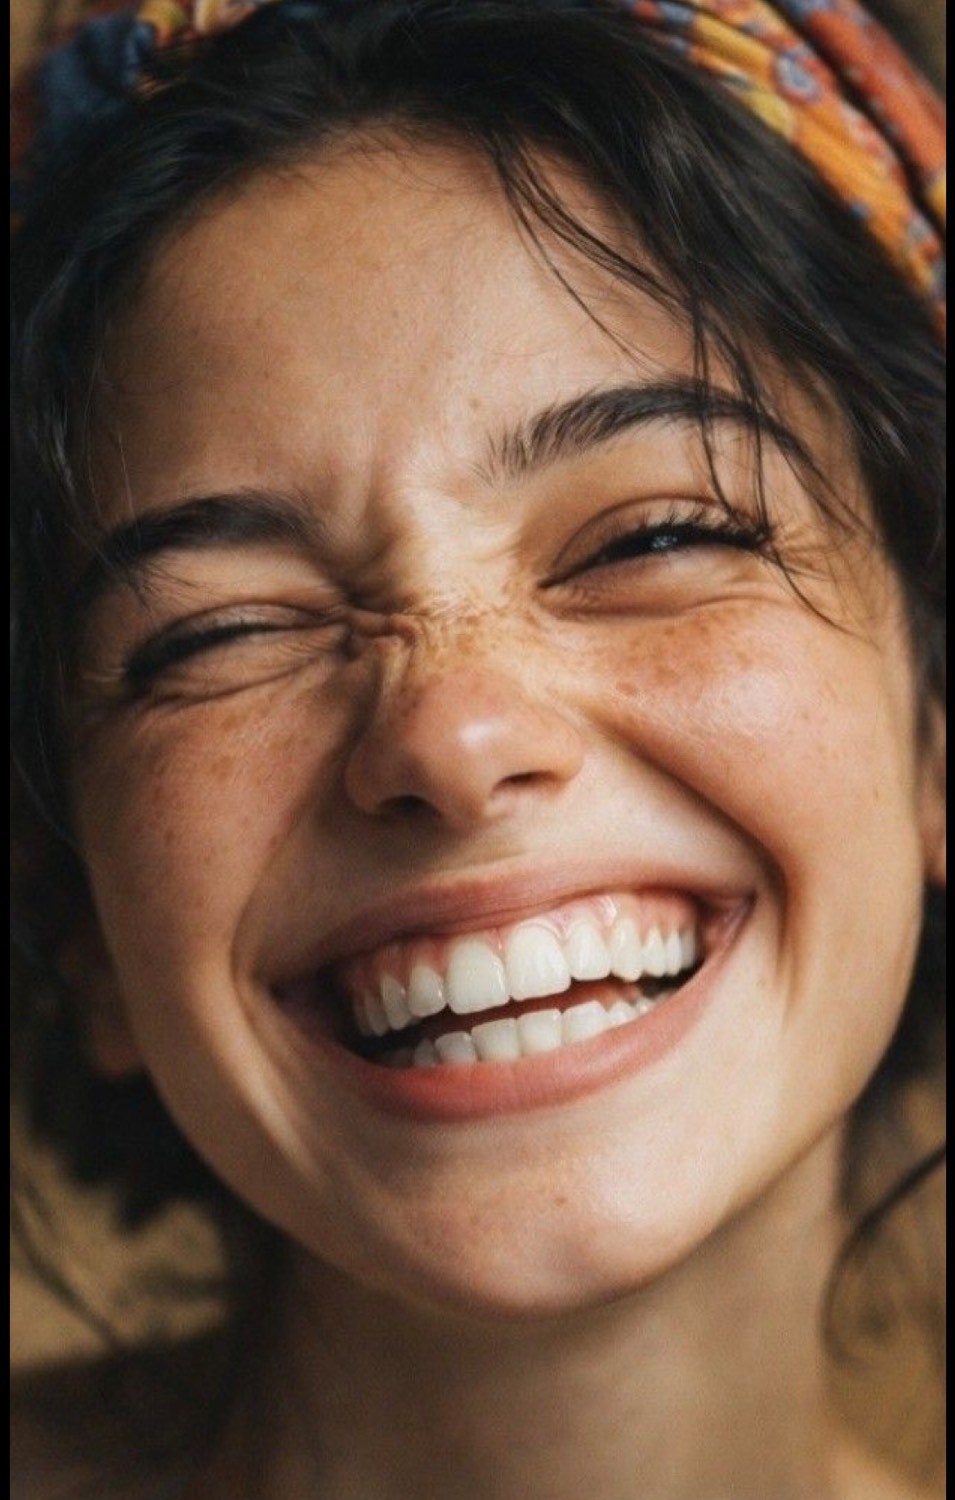

Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5


26-10-17 10:36:44 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


100%|██████████| 5.98M/5.98M [00:00<00:00, 123MB/s]


Detected emotion: happy
Emotion scores: {'angry': np.float32(2.3897753e-09), 'disgust': np.float32(5.58825e-19), 'fear': np.float32(0.09260649), 'happy': np.float32(99.907394), 'sad': np.float32(5.3089526e-08), 'surprise': np.float32(6.215745e-10), 'neutral': np.float32(4.4567027e-11)}


In [8]:
uploaded = files.upload()

image_path = next(iter(uploaded))

display(Image.open(image_path))

result = DeepFace.analyze(
    img_path=image_path,
    actions=["emotion"],
    enforce_detection=True
)

print("Detected emotion:", result[0]["dominant_emotion"])
print("Emotion scores:", result[0]["emotion"])

In [9]:
uploaded = files.upload()
image_path = next(iter(uploaded))

result = DeepFace.analyze(
    img_path=image_path,
    actions=["emotion"],
    enforce_detection=True
)

emotion_scores = result[0]["emotion"]

required_emotions = {
    "happy": "شاد",
    "sad": "غمگین",
    "angry": "عصبانی",
    "surprise": "متعجب",
    "neutral": "خنثی"
}

# Keep only the five required emotions
filtered_scores = {
    emotion: emotion_scores[emotion]
    for emotion in required_emotions
}

predicted_emotion = max(
    filtered_scores,
    key=filtered_scores.get
)

print("Detected mood:", required_emotions[predicted_emotion])
print("Emotion scores:", filtered_scores)

Saving IMG_9443.jpeg to IMG_9443 (1).jpeg
Detected mood: شاد
Emotion scores: {'happy': np.float32(99.907394), 'sad': np.float32(5.3089526e-08), 'angry': np.float32(2.3897753e-09), 'surprise': np.float32(6.215745e-10), 'neutral': np.float32(4.4567027e-11)}


In [11]:
data = pd.read_json("/content/movies_sample.json")
data

,id,title,title_fa,year,genres,moods,rating,poster
0,1,Inside Out,درون و بیرون,2015,"[animation, comedy, drama]","[happy, sad]",8.1,
1,2,The Intouchables,دست‌نیافتنی‌ها,2011,"[comedy, drama]","[sad, neutral]",8.5,
2,3,Up,بالا,2009,"[animation, adventure]","[sad, happy]",8.3,
3,4,The Grand Budapest Hotel,هتل بزرگ بوداپست,2014,[comedy],"[happy, neutral]",8.1,
4,5,Interstellar,میان‌ستاره‌ای,2014,"[sci-fi, drama]","[surprise, neutral]",8.7,
5,6,Inception,تلقین,2010,"[sci-fi, action]",[surprise],8.8,
6,7,The Pursuit of Happyness,در جستجوی خوشبختی,2006,[drama],[sad],8.0,
7,8,Coco,کوکو,2017,"[animation, music]","[sad, happy]",8.4,
8,9,Paddington 2,پدینگتون ۲,2017,"[comedy, family]","[sad, angry]",7.8,
9,10,Mad Max: Fury Road,مکس دیوانه: جاده خشم,2015,[action],[angry],8.1,


In [12]:
data.shape

(24, 8)

In [13]:
data.columns

Index(['id', 'title', 'title_fa', 'year', 'genres', 'moods', 'rating',
       'poster'],
      dtype='object')

In [ ]:
data.info()

In [ ]:
data.isnull().sum().sum()

In [14]:
data["moods"].value_counts()

,count
moods,
"[sad, happy]",5
"[sad, neutral]",3
[surprise],3
"[surprise, neutral]",3
[angry],2
"[happy, neutral]",2
"[happy, sad]",1
[sad],1
"[sad, angry]",1


In [15]:
for i in data.columns:
  if data[i].dtype == "object":
    print(data[i].value_counts())

title
Inside Out                  1
The Intouchables            1
Up                          1
The Grand Budapest Hotel    1
Interstellar                1
Inception                   1
The Pursuit of Happyness    1
Coco                        1
Paddington 2                1
Mad Max: Fury Road          1
The Shawshank Redemption    1
A Separation                1
Children of Heaven          1
Spirited Away               1
The Truman Show             1
Zootopia                    1
Forrest Gump                1
The Martian                 1
Ratatouille                 1
Knives Out                  1
Soul                        1
John Wick                   1
The Lion King               1
Parasite                    1
Name: count, dtype: int64
title_fa
درون و بیرون            1
دست‌نیافتنی‌ها          1
بالا                    1
هتل بزرگ بوداپست        1
میان‌ستاره‌ای           1
تلقین                   1
در جستجوی خوشبختی       1
کوکو                    1
پدینگتون ۲              1
مکس د

In [16]:
print(list(data.columns))

['id', 'title', 'title_fa', 'year', 'genres', 'moods', 'rating', 'poster']


In [17]:
genres_encoder = preprocessing.MultiLabelBinarizer()
moods_encoder = preprocessing.MultiLabelBinarizer()

genres_encoded = genres_encoder.fit_transform(data["genres"])
moods_encoded = moods_encoder.fit_transform(data["moods"])

genres_data = pd.DataFrame(genres_encoded,columns=genres_encoder.classes_,index=data.index)
moods_data = pd.DataFrame(moods_encoded,columns=moods_encoder.classes_,index=data.index)

X = pd.concat([genres_data.add_prefix("genre_"),moods_data.add_prefix("mood_")],axis=1)

display(X.head())
print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

,genre_action,genre_adventure,genre_animation,genre_comedy,genre_drama,genre_family,genre_fantasy,genre_music,genre_mystery,genre_romance,genre_sci-fi,genre_thriller,mood_angry,mood_happy,mood_neutral,mood_sad,mood_surprise
0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0
1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0
2,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
3,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0
4,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1


Shape: (24, 17)
Missing values: 0


In [18]:
x = pd.concat([genres_data, moods_data], axis=1)
print(x.head())
print(x.shape)

   action  adventure  animation  comedy  drama  family  fantasy  music  \
0       0          0          1       1      1       0        0      0   
1       0          0          0       1      1       0        0      0   
2       0          1          1       0      0       0        0      0   
3       0          0          0       1      0       0        0      0   
4       0          0          0       0      1       0        0      0   

   mystery  romance  sci-fi  thriller  angry  happy  neutral  sad  surprise  
0        0        0       0         0      0      1        0    1         0  
1        0        0       0         0      0      0        1    1         0  
2        0        0       0         0      0      1        0    1         0  
3        0        0       0         0      0      1        1    0         0  
4        0        0       1         0      0      0        1    0         1  
(24, 17)


In [19]:
print(genres_data.shape)
print(moods_data.shape)

print(genres_data.head())
print(moods_data.head())

(24, 12)
(24, 5)
   action  adventure  animation  comedy  drama  family  fantasy  music  \
0       0          0          1       1      1       0        0      0   
1       0          0          0       1      1       0        0      0   
2       0          1          1       0      0       0        0      0   
3       0          0          0       1      0       0        0      0   
4       0          0          0       0      1       0        0      0   

   mystery  romance  sci-fi  thriller  
0        0        0       0         0  
1        0        0       0         0  
2        0        0       0         0  
3        0        0       0         0  
4        0        0       1         0  
   angry  happy  neutral  sad  surprise
0      0      1        0    1         0
1      0      0        1    1         0
2      0      1        0    1         0
3      0      1        1    0         0
4      0      0        1    0         1


In [20]:
similarity_matrix = cosine_similarity(x)
print("shape", similarity_matrix.shape)
print(similarity_matrix)

shape (24, 24)
[[1.         0.67082039 0.67082039 0.51639778 0.2236068  0.
  0.63245553 0.67082039 0.4472136  0.         0.51639778 0.31622777
  0.67082039 0.2236068  0.51639778 0.67082039 0.67082039 0.2236068
  0.77459667 0.2236068  0.67082039 0.         0.89442719 0.25819889]
 [0.67082039 1.         0.25       0.57735027 0.5        0.
  0.70710678 0.25       0.5        0.         0.8660254  0.70710678
  0.5        0.25       0.57735027 0.25       0.5        0.25
  0.28867513 0.5        0.75       0.         0.5        0.28867513]
 [0.67082039 0.25       1.         0.28867513 0.         0.
  0.35355339 0.75       0.25       0.         0.28867513 0.
  0.5        0.25       0.         0.5        0.5        0.5
  0.57735027 0.         0.5        0.         0.75       0.        ]
 [0.51639778 0.57735027 0.28867513 1.         0.28867513 0.
  0.         0.28867513 0.28867513 0.         0.33333333 0.40824829
  0.28867513 0.28867513 0.33333333 0.57735027 0.28867513 0.57735027
  0.66666667 0.5

In [21]:
print(data.columns.tolist())
print(data["title"].head(10).tolist())

['id', 'title', 'title_fa', 'year', 'genres', 'moods', 'rating', 'poster']
['Inside Out', 'The Intouchables', 'Up', 'The Grand Budapest Hotel', 'Interstellar', 'Inception', 'The Pursuit of Happyness', 'Coco', 'Paddington 2', 'Mad Max: Fury Road']


In [22]:
movie_title = "Inside Out"
movie_index = data.index[data["title"] == movie_title][0]
print("movie index : ", movie_index)

movie index :  0


In [23]:
similarities = similarity_matrix[movie_index]
similar_movies_indices = similarities.argsort()[::-1][1:6]
recommended_movies = data.iloc[similar_movies_indices]
print(recommended_movies[["title", "title_fa", "rating"]])

                 title       title_fa  rating
22       The Lion King         شیرشاه     8.5
18         Ratatouille     موش سرآشپز     8.1
16        Forrest Gump     فارست گامپ     8.8
12  Children of Heaven  بچه‌های آسمان     8.2
7                 Coco           کوکو     8.4


In [28]:
for i in similar_movies_indices:
    print(data.loc[i, "title"], "->", similarity_matrix[movie_index, i])

The Lion King -> 0.8944271909999159
Ratatouille -> 0.7745966692414835
Forrest Gump -> 0.6708203932499369
Children of Heaven -> 0.6708203932499369
Coco -> 0.6708203932499369


In [24]:
for mood in moods_encoder.classes_:
    count = X[f"mood_{mood}"].sum()
    print(f"{mood}: {count} movies")

angry: 4 movies
happy: 10 movies
neutral: 9 movies
sad: 11 movies
surprise: 6 movies


In [25]:
def recommend_by_mood(mood, n=5):
    mood_column = f"mood_{mood}"
    if mood_column not in X.columns:
        raise ValueError("Invalid mood!")
    matching_indices = X.index[X[mood_column] == 1].tolist()
    matching_indices = sorted(matching_indices,key=lambda i: data.loc[i, "rating"],reverse=True)
    recommended_indices = matching_indices[:n]

    if len(recommended_indices) < n:
        remaining_indices = [i for i in data.index if i not in recommended_indices]
        remaining_indices = sorted(remaining_indices,key=lambda i: data.loc[i, "rating"],reverse=True)
        needed = n - len(recommended_indices)
        recommended_indices.extend(remaining_indices[:needed])
    return data.loc[recommended_indices,["title", "title_fa", "year", "rating"]]

In [26]:
recommend_by_mood("angry")

,title,title_fa,year,rating
9,Mad Max: Fury Road,مکس دیوانه: جاده خشم,2015,8.1
15,Zootopia,زوتوپیا,2016,8.0
8,Paddington 2,پدینگتون ۲,2017,7.8
21,John Wick,جان ویک,2014,7.4
10,The Shawshank Redemption,رستگاری در شاوشنک,1994,9.3


In [27]:
detected_mood_fa = required_emotions[predicted_emotion]
recommendations = recommend_by_mood(predicted_emotion)
print("\nاحساس تشخیص‌داده‌شده:", detected_mood_fa)
print("\nفیلم‌های پیشنهادی:")
display(recommendations[["title", "title_fa", "year", "rating"]])


احساس تشخیص‌داده‌شده: شاد

فیلم‌های پیشنهادی:


,title,title_fa,year,rating
16,Forrest Gump,فارست گامپ,1994,8.8
22,The Lion King,شیرشاه,1994,8.5
7,Coco,کوکو,2017,8.4
2,Up,بالا,2009,8.3
12,Children of Heaven,بچه‌های آسمان,1997,8.2


In [32]:
data.to_json("movies.json",orient="records",force_ascii=False,indent=2)
np.save("similarity_matrix.npy",similarity_matrix)
print("اطلاعات فیلم ها و ماتریس شباهت ها ذخیره شدند")

اطلاعات فیلم ها و ماتریس شباهت ها ذخیره شدند


In [33]:
files.download("movies.json")
files.download("similarity_matrix.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>